In [ ]:
import pandas as pd
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.linear_model import LinearRegression
from sklearn.ensemble import RandomForestRegressor
from xgboost import XGBRegressor
from sklearn.metrics import r2_score, mean_absolute_error, mean_absolute_percentage_error

import warnings
warnings.filterwarnings('ignore')

In [ ]:
df = pd.read_csv('data/companies_revenue_data.csv')
print(df.shape)
df.head()

(292, 12)


,report_id,company,fiscal_year,quarter,revenue_usd,op_margin_%,headcount,revenue_lag1,revenue_lag2,qoq_growth,yoy_growth,target_revenue
0,TCS_2015_Q1,TCS,2015,Q1,3694.0,26.3,305431.0,NaN,NaN,NaN,NaN,3929.0
1,TCS_2015_Q2,TCS,2015,Q2,3929.0,26.8,313757.0,3694.0,NaN,6.4,NaN,3931.0
2,TCS_2015_Q3,TCS,2015,Q3,3931.0,27.0,318625.0,3929.0,NaN,0.1,NaN,3900.0
3,TCS_2015_Q4,TCS,2015,Q4,3900.0,27.2,319656.0,3931.0,NaN,-0.8,NaN,4036.0
4,TCS_2016_Q1,TCS,2016,Q1,4036.0,26.3,324935.0,3900.0,3694.0,3.5,9.3,4156.0


In [3]:
def column_summary(df):
    
    summary_df = pd.DataFrame({
        'col_name' : df.columns,
        'col_dtype' : df.dtypes.values,
        'num_of_nulls' : df.isnull().sum().values,
        'null%' : round((df.isnull().sum()/df.shape[0])*100, 2).values,
        'num_of_non_nulls' : df.count().values,
        'num_of_distinct_values' : df.nunique().values
    })
    
    ## extracting distinct_values_counts for summary_df
    distinct_values_counts = []
    for i in range(df.shape[1]):
        if summary_df['num_of_distinct_values'][i]<=10:
            distinct_values_counts.append(dict(zip(df[df.columns[i]].value_counts().index.to_list(),df[df.columns[i]].value_counts().values)))
        else:
            distinct_values_counts.append(dict(zip(df[df.columns[i]].value_counts().index.to_list()[:10],df[df.columns[i]].value_counts().values[:10])))
            
    summary_df['distinct_values_counts'] = distinct_values_counts
    
    return summary_df

In [4]:
column_summary(df)

,col_name,col_dtype,num_of_nulls,null%,num_of_non_nulls,num_of_distinct_values,distinct_values_counts
0,report_id,object,0,0.00,292,292,"{'TCS_2015_Q1': 1, 'Cognizant_2019_Q4': 1, 'Co..."
1,company,object,0,0.00,292,7,"{'TCS': 44, 'HCLTech': 44, 'Wipro': 44, 'Infos..."
2,fiscal_year,int64,0,0.00,292,11,"{2018: 28, 2019: 28, 2020: 28, 2021: 28, 2022:..."
3,quarter,object,0,0.00,292,4,"{'Q1': 73, 'Q2': 73, 'Q3': 73, 'Q4': 73}"
4,revenue_usd,float64,3,1.03,289,286,"{1668.0: 2, 2543.0: 2, 1491.0: 2, 4744.0: 1, 4..."
5,op_margin_%,float64,3,1.03,289,137,"{14.2: 7, 15.2: 6, 25.1: 6, 16.1: 6, 17.0: 5, ..."
6,headcount,float64,3,1.03,289,288,"{336300.0: 2, 305431.0: 1, 345600.0: 1, 355300..."
7,revenue_lag1,float64,8,2.74,284,281,"{2543.0: 2, 1491.0: 2, 1668.0: 2, 4897.0: 1, 4..."
8,revenue_lag2,float64,28,9.59,264,261,"{1491.0: 2, 1668.0: 2, 2543.0: 2, 3694.0: 1, 4..."
9,qoq_growth,float64,10,3.42,282,104,"{2.3: 8, 3.2: 8, 0.7: 7, 1.8: 7, -1.4: 7, 0.8:..."


In [5]:
# adding calender parameters
df

,report_id,company,fiscal_year,quarter,revenue_usd,op_margin_%,headcount,revenue_lag1,revenue_lag2,qoq_growth,yoy_growth,target_revenue
0,TCS_2015_Q1,TCS,2015,Q1,3694.0,26.3,305431.0,NaN,NaN,NaN,NaN,3929.0
1,TCS_2015_Q2,TCS,2015,Q2,3929.0,26.8,313757.0,3694.0,NaN,6.4,NaN,3931.0
2,TCS_2015_Q3,TCS,2015,Q3,3931.0,27.0,318625.0,3929.0,NaN,0.1,NaN,3900.0
3,TCS_2015_Q4,TCS,2015,Q4,3900.0,27.2,319656.0,3931.0,NaN,-0.8,NaN,4036.0
4,TCS_2016_Q1,TCS,2016,Q1,4036.0,26.3,324935.0,3900.0,3694.0,3.5,9.3,4156.0
...,...,...,...,...,...,...,...,...,...,...,...,...
287,TechMahindra_2024_Q4,TechMahindra,2024,Q4,1548.0,7.4,145455.0,1573.0,1668.0,-1.6,-7.2,1559.0
288,TechMahindra_2025_Q1,TechMahindra,2025,Q1,1559.0,8.5,147620.0,1548.0,1601.0,0.7,-2.6,1589.0
289,TechMahindra_2025_Q2,TechMahindra,2025,Q2,1589.0,9.6,154273.0,1559.0,1555.0,1.9,2.2,1567.0
290,TechMahindra_2025_Q3,TechMahindra,2025,Q3,1567.0,10.2,150488.0,1589.0,1573.0,-1.4,-0.4,1549.0


In [6]:
# dropping null rows
df.dropna(inplace=True)

In [7]:
column_summary(df)

,col_name,col_dtype,num_of_nulls,null%,num_of_non_nulls,num_of_distinct_values,distinct_values_counts
0,report_id,object,0,0.0,254,254,"{'TCS_2016_Q1': 1, 'Cognizant_2023_Q3': 1, 'Co..."
1,company,object,0,0.0,254,7,"{'TCS': 39, 'HCLTech': 39, 'Wipro': 39, 'Infos..."
2,fiscal_year,int64,0,0.0,254,10,"{2019: 28, 2020: 28, 2021: 28, 2022: 28, 2023:..."
3,quarter,object,0,0.0,254,4,"{'Q1': 66, 'Q2': 65, 'Q3': 64, 'Q4': 59}"
4,revenue_usd,float64,0,0.0,254,252,"{1668.0: 2, 2543.0: 2, 4777.0: 1, 4886.0: 1, 4..."
5,op_margin_%,float64,0,0.0,254,126,"{16.1: 6, 15.2: 6, 14.2: 6, 20.1: 5, 25.1: 5, ..."
6,headcount,float64,0,0.0,254,253,"{336300.0: 2, 324935.0: 1, 346600.0: 1, 281200..."
7,revenue_lag1,float64,0,0.0,254,252,"{2543.0: 2, 1668.0: 2, 3900.0: 1, 4777.0: 1, 4..."
8,revenue_lag2,float64,0,0.0,254,251,"{1491.0: 2, 1668.0: 2, 2543.0: 2, 3694.0: 1, 4..."
9,qoq_growth,float64,0,0.0,254,100,"{2.3: 8, -1.4: 7, 3.2: 7, 0.7: 7, 0.6: 6, 1.0:..."


In [8]:
# train_test_split
train = df[df['fiscal_year']!=2025].drop(['report_id'], axis=1)
test = df[df['fiscal_year']==2025].drop(['report_id'], axis=1)

X_train, y_train = train.drop(['target_revenue'], axis=1), train['target_revenue']
X_test, y_test = test.drop(['target_revenue'], axis=1), test['target_revenue']

In [12]:
# defining columns
num_cols = ['fiscal_year', 'revenue_usd', 'op_margin_%', 'headcount', 'revenue_lag1', 'revenue_lag2', 'qoq_growth', 'yoy_growth']
cat_cols = ['company', 'quarter']


# creating trfs
cat_transformer = Pipeline(steps=[
    ("onehot", OneHotEncoder(handle_unknown="ignore"))
])

num_transformer = Pipeline(steps=[
    ("scaler", StandardScaler())
])

# defining preprocessor
preprocessor = ColumnTransformer(
        transformers=[
            ("num", num_transformer, num_cols),
            ("cat", cat_transformer, cat_cols),
        ],
        remainder="drop"
    )

#### Linear Regression :

In [18]:
# creating pipeline
model = LinearRegression()

pipe = Pipeline(steps=[
        ("preprocess", preprocessor),
        ("model", model)
    ])

pipe.fit(X_train, y_train)
train_pred = pipe.predict(X_train)
test_pred = pipe.predict(X_test)

# evaluating metrics
print(r2_score(y_train, train_pred))
print(r2_score(y_test, test_pred))
print(mean_absolute_error(y_train, train_pred))
print(mean_absolute_error(y_test, test_pred))
print(mean_absolute_percentage_error(y_train, train_pred))
print(mean_absolute_percentage_error(y_test, test_pred))

0.9974491418375513
0.9973660390930085
113.27546583435414
140.42924292929865
0.025373063538755448
0.02429312782083212


### Visual Representation:

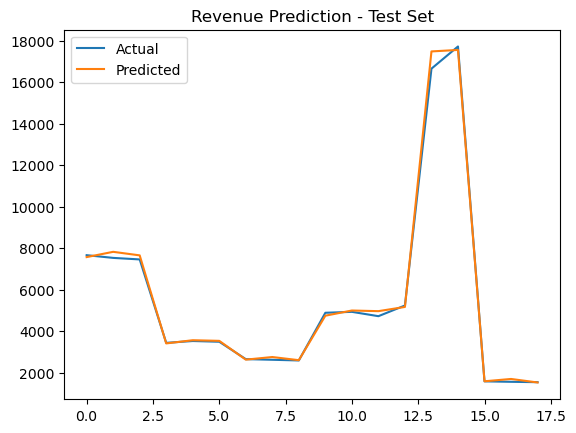

In [19]:
import matplotlib.pyplot as plt

plt.plot(y_test.values, label="Actual")
plt.plot(test_pred, label="Predicted")
plt.legend()
plt.title("Revenue Prediction - Test Set")
plt.show()

### Prediction on 2026 Data:

In [21]:
# creating query
temp = pd.read_csv('data/companies_revenue_data_V1.csv')
query = temp[(temp['fiscal_year']==2025) & (temp['quarter']=='Q4')].drop(['report_id', 'target_revenue'], axis=1)

In [70]:
pipe.predict(query)

array([7461.84781849, 3462.25346103, 2623.72525125])

In [24]:
pipe.predict(query)

array([ 7581.583 ,  3444.5876,  2525.808 ,  4668.    , 17117.666 ,
       17528.668 ,  1571.5808], dtype=float32)